# Pergunta de pesquisa 1
---

Qual é a taxa de acerto ($Pass@1$, $T=0$) das LLMs na resolução textual dos problemas da OBI (Nível Sênior) e como esse desempenho varia entre as 5 linguagens de programação avaliadas (Python, C++, C, Java e JavaScript)?

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import json
from codebleu import calc_codebleu

In [15]:
questions_path = []

path_database = Path('../database/dataset_obi_senior/')

for path_question in sorted(path_database.glob("*")):
    if path_question.is_dir():
        questions_path.append(path_question)
        print(path_question.name)

problems = []

for question_path in questions_path:
    problems.append(json.loads(Path(question_path / "problem.json").read_text(encoding="utf-8")))

A idade de Dona Mônica
Acelerador de partículas
Alfabeto Alienígena
Aplicativo de calorias
Arara!
Arco e flecha
Arranha-céu
Baralho
Barcos da Nlogônia
Bingo!
Botas Trocadas
Brigadeiros
Burocracia
Cafeteria
Calçada Imperial
Camisetas da Olimpíada
Candidatas
Caravana
Carrinho
Chaves
Chuva
Chuva_2019
Chuva_2022
Ciclovias
Computador
Concurso
Construtora
Construção de Rodovia
Contas a pagar
Cortando o Papel
Cubo Preto
Código
Dança de Formatura
Dario e Xerxes
Direção
Dividindo o império
Divisão do Tesouro
Dona Formiga
Dona Minhoca
Dona Minhoca_2022
Dupla de tênis
Dígitos
Emoticons
Energia
Escadaria
Estoque
Estrada
Etiquetas
Falha de segurança
Fast-Food
Feira de Artesanato
Festa Junina
Festa olímpica
Fila
Fissura Perigosa
Fotografia
Fotos de Relíquias
Frete
Game Show
Game-10
Garamana
Grupos de Trabalho
Gráfico de Barras
Harmonia Nasal
Hidrovias e Rodovias
Hotel
Intervalo Distinto
Irmãos
Jardim de infância
Jogo da Vida
Jogo de Pratos
Jogo do Poder
Jogo do Preto e Branco
Lista palíndroma
Lâmpad

In [16]:
models_fs = [
    "deepseek_deepseek-v4.1-flash",
    "gemini-3.8-flash",
    "openai_gpt-6-luna",
    "z-ai_glm-5.3-flash"
]
languages_fs = ["python", "cpp", "c", "java", "javascript"]
missing_count = 0

for question_path in questions_path:
    for lang in languages_fs:
        for m in models_fs:
            code_path = Path(f"../results/dataset_obi_senior/{m}/zero_shot/{lang}/text/{question_path.name}.json")
            if not code_path.exists():
                print(f"[{m} - {lang}]: {question_path.name}")
                missing_count += 1

if missing_count == 0:
    print("Verificando arquivos gerados pelas LLMs...")
    print("Todos os arquivos JSON de código existem para todos os modelos e linguagens!")

Verificando arquivos gerados pelas LLMs...
Todos os arquivos JSON de código existem para todos os modelos e linguagens!


In [17]:
count_dificulty = {}

df_problems = pd.DataFrame(problems)

for level in df_problems["level"].unique():
    cases = df_problems[df_problems["level"] == level]
    count_dificulty[level] = len(cases)

In [18]:
print(count_dificulty)

{'senior': 125}


In [19]:
def read_csv(path: Path) -> pd.DataFrame:
    try:
        return pd.read_csv(path)
    except:
        return None

In [20]:
languages = ["Python", "C++", "C", "Java", "JavaScript"]
TOTAL_PROBLEMS = 125
verdicts = ['AC', 'WA', 'RE', 'TLE', 'MLE', 'CE']

def count_ac_by_language(data: pd.DataFrame, languages: list, problems_per_lang: int = 125) -> dict:
    counts = {}
    for i, lang in enumerate(languages):
        sub_df = data.iloc[i * problems_per_lang : (i + 1) * problems_per_lang]
        ac = (sub_df["judge_predict"] == "AC").sum()
        counts[lang] = int(ac)
    counts["Média"] = float(np.mean([counts[l] for l in languages]))
    counts["Total"] = int(sum(counts[l] for l in languages))
    return counts

In [21]:
model_paths = {
    "DeepSeek v4.1 Flash": Path("../results/dataset_obi_senior/judge/deepseek_deepseek-v4.1-flash.csv"),
    "Gemini 3.8 Flash": Path("../results/dataset_obi_senior/judge/gemini-3.8-flash.csv"),
    "GPT-6 Luna": Path("../results/dataset_obi_senior/judge/openai_gpt-6-luna.csv"),
    "GLM 5.3 Flash": Path("../results/dataset_obi_senior/judge/z-ai_glm-5.3-flash.csv")
}

datas = {}
results = {}

for name, path in model_paths.items():
    df = read_csv(path)
    if df is not None:
        # Identifica a linguagem em cada bloco de 125 linhas
        df["language"] = [languages[i // TOTAL_PROBLEMS] for i in range(len(df))]
        datas[name] = df
        results[name] = count_ac_by_language(df, languages, TOTAL_PROBLEMS)

In [22]:
for name, data in datas.items():
    print(f"{name}: {len(data)} linhas ({len(data) // TOTAL_PROBLEMS} linguagens x {TOTAL_PROBLEMS} problemas)")
    names_in_csv = set(data["question_name"])
    missing_in_csv = [q.name for q in questions_path if q.name not in names_in_csv]
    if missing_in_csv:
        print(f"  Faltando no CSV ({len(missing_in_csv)}): {missing_in_csv[:3]}")
    else:
        print("  Todas as 125 questões estão presentes no CSV.")

DeepSeek v4.1 Flash: 625 linhas (5 linguagens x 125 problemas)
  Todas as 125 questões estão presentes no CSV.
Gemini 3.8 Flash: 625 linhas (5 linguagens x 125 problemas)
  Todas as 125 questões estão presentes no CSV.
GPT-6 Luna: 625 linhas (5 linguagens x 125 problemas)
  Todas as 125 questões estão presentes no CSV.
GLM 5.3 Flash: 625 linhas (5 linguagens x 125 problemas)
  Todas as 125 questões estão presentes no CSV.


In [23]:
# Tabela com as quantidades absolutas de AC (de 125 por linguagem)
df_ac_count = pd.DataFrame(results).T[["Python", "C++", "C", "Java", "JavaScript", "Média", "Total"]]
df_ac_count.columns = ["Python", "C++", "C", "Java", "JavaScript", "Média de AC", "Total AC (em 625)"]

# Tabela com as porcentagens de acerto (Pass@1)
df_ac_pct = pd.DataFrame(results).T[["Python", "C++", "C", "Java", "JavaScript", "Média"]]
for col in df_ac_pct.columns:
    df_ac_pct[col] = df_ac_pct[col].apply(lambda v: f"{(v / TOTAL_PROBLEMS) * 100:.2f}%")
df_ac_pct.columns = ["Python", "C++", "C", "Java", "JavaScript", "Média (Pass@1)"]

print("Quantidade Absoluta de AC (Accepted de 125 problemas por linguagem):")
display(df_ac_count)

print("\nTaxa de Acerto (%) (Pass@1, T=0):")
display(df_ac_pct)

Quantidade Absoluta de AC (Accepted de 125 problemas por linguagem):


,Python,C++,C,Java,JavaScript,Média de AC,Total AC (em 625)
DeepSeek v4.1 Flash,118.0,119.0,121.0,118.0,120.0,119.2,596.0
Gemini 3.8 Flash,121.0,120.0,115.0,115.0,118.0,117.8,589.0
GPT-6 Luna,106.0,113.0,105.0,106.0,117.0,109.4,547.0
GLM 5.3 Flash,100.0,112.0,104.0,107.0,85.0,101.6,508.0



Taxa de Acerto (%) (Pass@1, T=0):


,Python,C++,C,Java,JavaScript,Média (Pass@1)
DeepSeek v4.1 Flash,94.40%,95.20%,96.80%,94.40%,96.00%,95.36%
Gemini 3.8 Flash,96.80%,96.00%,92.00%,92.00%,94.40%,94.24%
GPT-6 Luna,84.80%,90.40%,84.00%,84.80%,93.60%,87.52%
GLM 5.3 Flash,80.00%,89.60%,83.20%,85.60%,68.00%,81.28%


In [24]:
# Tabela de Valores Possíveis do Judge
judge_desc = {
    "Veredito": verdicts,
    "Nome Completo": [
        "Accepted",
        "Wrong Answer",
        "Runtime Error",
        "Time Limit Exceeded",
        "Memory Limit Exceeded",
        "Compilation Error"
    ],
    "Descrição": [
        "Solução correta em 100% dos casos de teste",
        "Saída divergente do gabarito oficial em um ou mais testes",
        "Erro de execução / crash / exceção não tratada",
        "Tempo limite de execução por caso de teste excedido",
        "Consumo de memória RAM excedeu o limite estipulado",
        "Falha durante a compilação do código fonte"
    ]
}
df_judge_desc = pd.DataFrame(judge_desc)

# Distribuição geral dos vereditos por LLM
rows_verdicts = []
for name, df in datas.items():
    vc = df['judge_predict'].value_counts().to_dict()
    r = {'LLM': name}
    for v in verdicts:
        c = vc.get(v, 0)
        pct = (c / len(df)) * 100
        r[v] = f"{c} ({pct:.1f}%)"
    r['Total'] = len(df)
    rows_verdicts.append(r)
df_all_verdicts = pd.DataFrame(rows_verdicts)

print("Valores Possíveis do Judge:")
display(df_judge_desc)

print("\nDistribuição Geral dos Vereditos por LLM (Total de 625 execuções):")
display(df_all_verdicts)

Valores Possíveis do Judge:


,Veredito,Nome Completo,Descrição
0,AC,Accepted,Solução correta em 100% dos casos de teste
1,WA,Wrong Answer,Saída divergente do gabarito oficial em um ou ...
2,RE,Runtime Error,Erro de execução / crash / exceção não tratada
3,TLE,Time Limit Exceeded,Tempo limite de execução por caso de teste exc...
4,MLE,Memory Limit Exceeded,Consumo de memória RAM excedeu o limite estipu...
5,CE,Compilation Error,Falha durante a compilação do código fonte



Distribuição Geral dos Vereditos por LLM (Total de 625 execuções):


,LLM,AC,WA,RE,TLE,MLE,CE,Total
0,DeepSeek v4.1 Flash,596 (95.4%),21 (3.4%),4 (0.6%),0 (0.0%),0 (0.0%),4 (0.6%),625
1,Gemini 3.8 Flash,589 (94.2%),25 (4.0%),4 (0.6%),0 (0.0%),2 (0.3%),5 (0.8%),625
2,GPT-6 Luna,547 (87.5%),54 (8.6%),7 (1.1%),7 (1.1%),1 (0.2%),9 (1.4%),625
3,GLM 5.3 Flash,508 (81.3%),45 (7.2%),28 (4.5%),4 (0.6%),0 (0.0%),40 (6.4%),625


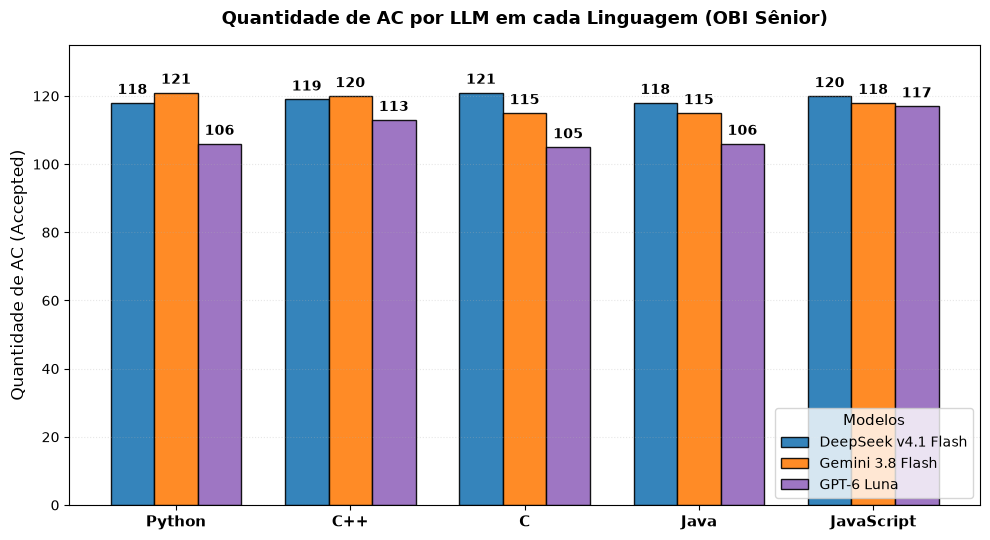

In [25]:
# Gráfico 1: Quantidade de AC por Linguagem (DeepSeek, Gemini, GPT-6 Luna)
main_models = ["DeepSeek v4.1 Flash", "Gemini 3.8 Flash", "GPT-6 Luna"]
main_colors = ["#1f77b4", "#ff7f0e", "#9467bd"]

fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.arange(len(languages))
width = 0.25

for i, (model, color) in enumerate(zip(main_models, main_colors)):
    vals = [results[model][lang] for lang in languages]
    offset = (i - 1) * width
    rects = ax.bar(x + offset, vals, width, label=model, color=color, edgecolor="black", alpha=0.9)
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f"{int(h)}",
                    xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 4), textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylabel("Quantidade de AC (Accepted)", fontsize=12)
ax.set_title("Quantidade de AC por LLM em cada Linguagem (OBI Sênior)", fontsize=13, fontweight="bold", pad=15)
ax.set_xticks(x)
ax.set_xticklabels(languages, fontsize=11, fontweight="bold")
ax.set_ylim(0, 135)
ax.legend(title="Modelos", loc="lower right", fontsize=10, title_fontsize=11)
ax.grid(axis="y", linestyle=":", alpha=0.3)

plt.tight_layout()
plt.show()

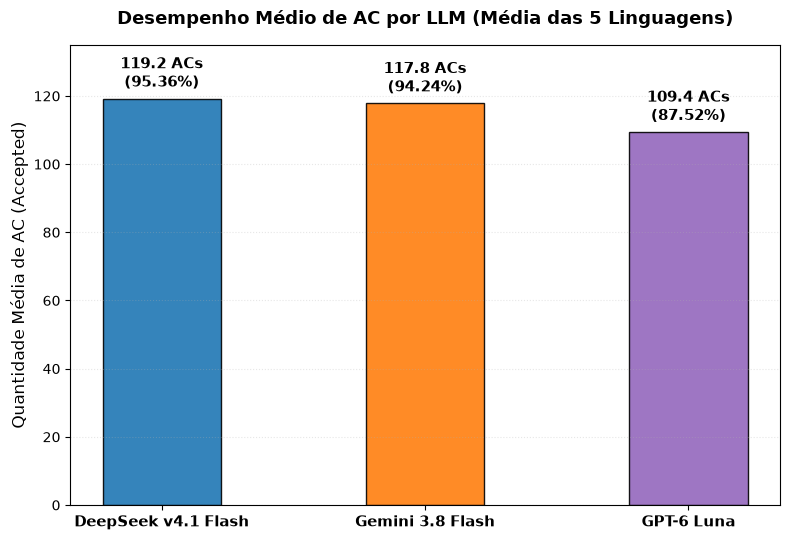

In [26]:
# Gráfico 2: Desempenho Médio de AC por LLM (DeepSeek, Gemini, GPT-6 Luna)
fig, ax = plt.subplots(figsize=(8, 5.5))

means_main = [results[m]["Média"] for m in main_models]
x_main = np.arange(len(main_models))
bars = ax.bar(x_main, means_main, color=main_colors, edgecolor="black", width=0.45, alpha=0.9)

for bar, m_val in zip(bars, means_main):
    pct = (m_val / TOTAL_PROBLEMS) * 100
    ax.annotate(f"{m_val:.1f} ACs\n({pct:.2f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, m_val),
                xytext=(0, 5), textcoords="offset points",
                ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_ylabel("Quantidade Média de AC (Accepted)", fontsize=12)
ax.set_title("Desempenho Médio de AC por LLM (Média das 5 Linguagens)", fontsize=13, fontweight="bold", pad=15)
ax.set_xticks(x_main)
ax.set_xticklabels(main_models, fontsize=11, fontweight="bold")
ax.set_ylim(0, 135)
ax.grid(axis="y", linestyle=":", alpha=0.3)

plt.tight_layout()
plt.show()

## Análise Isolada: GLM 5.3 Flash
---

Nesta seção, o desempenho do **GLM 5.3 Flash** é analisado separadamente, exibindo tanto o gráfico de acertos por linguagem quanto a tabela detalhada com a distribuição de todos os vereditos do judge (`AC`, `WA`, `RE`, `TLE`, `MLE`, `CE`).

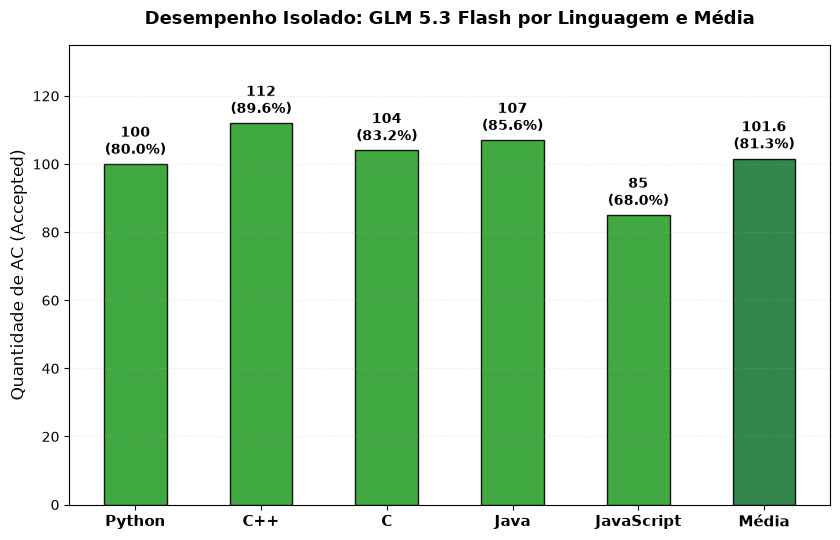

In [27]:
# Gráfico 3: Desempenho Isolado do GLM 5.3 Flash por Linguagem e Média
fig, ax = plt.subplots(figsize=(8.5, 5.5))
glm_cats = languages + ["Média"]
glm_vals = [results["GLM 5.3 Flash"][c] for c in glm_cats]
x_glm = np.arange(len(glm_cats))
glm_colors = ["#2ca02c" if c != "Média" else "#1b7837" for c in glm_cats]

bars_glm = ax.bar(x_glm, glm_vals, color=glm_colors, edgecolor="black", width=0.5, alpha=0.9)
for bar, val in zip(bars_glm, glm_vals):
    pct = (val / TOTAL_PROBLEMS) * 100
    lbl = f"{val:.1f}\n({pct:.1f}%)" if val % 1 != 0 else f"{int(val)}\n({pct:.1f}%)"
    ax.annotate(lbl,
                 xy=(bar.get_x() + bar.get_width() / 2, val),
                 xytext=(0, 4), textcoords="offset points",
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylabel("Quantidade de AC (Accepted)", fontsize=12)
ax.set_title("Desempenho Isolado: GLM 5.3 Flash por Linguagem e Média", fontsize=13, fontweight="bold", pad=15)
ax.set_xticks(x_glm)
ax.set_xticklabels(glm_cats, fontsize=11, fontweight="bold")
ax.set_ylim(0, 135)
ax.grid(axis="y", linestyle=":", alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
# Tabela detalhada dos vereditos do GLM 5.3 Flash por linguagem
df_glm = datas["GLM 5.3 Flash"]
rows_glm = []
for lang in languages:
    sub = df_glm[df_glm['language'] == lang]
    vc = sub['judge_predict'].value_counts().to_dict()
    r = {'Linguagem': lang}
    for v in verdicts:
        r[v] = vc.get(v, 0)
    r['Total'] = len(sub)
    r['Taxa AC (%)'] = f"{(r['AC'] / TOTAL_PROBLEMS) * 100:.2f}%"
    rows_glm.append(r)

tot_glm = {'Linguagem': 'Total Geral'}
vc_all = df_glm['judge_predict'].value_counts().to_dict()
for v in verdicts:
    tot_glm[v] = vc_all.get(v, 0)
tot_glm['Total'] = len(df_glm)
tot_glm['Taxa AC (%)'] = f"{(tot_glm['AC'] / len(df_glm)) * 100:.2f}%"
rows_glm.append(tot_glm)
df_glm_detail = pd.DataFrame(rows_glm)

print("Detalhamento dos Vereditos do Judge para o GLM 5.3 Flash por Linguagem:")
display(df_glm_detail)

Detalhamento dos Vereditos do Judge para o GLM 5.3 Flash por Linguagem:


,Linguagem,AC,WA,RE,TLE,MLE,CE,Total,Taxa AC (%)
0,Python,100,10,2,0,0,13,125,80.00%
1,C++,112,9,0,0,0,4,125,89.60%
2,C,104,7,0,2,0,12,125,83.20%
3,Java,107,9,2,2,0,5,125,85.60%
4,JavaScript,85,10,24,0,0,6,125,68.00%
5,Total Geral,508,45,28,4,0,40,625,81.28%


## 4. Análise Aprofundada & Insights Avançados da RQ1
---

Para responder de forma aprofundada à **Pergunta de Pesquisa 1**, esta seção investiga as razões qualitativas e estruturais por trás das taxas de acerto observadas. A análise abrange:
1. **Taxonomia dos Erros (Não-AC)**: Diagnóstico das causas de falha (`WA`, `CE`, `RE`, `TLE`, `MLE`).
2. **Degradação de Desempenho por Dificuldade (Fases da OBI)**: Como a complexidade algorítmica (Fase 1 vs Fase 2 vs Fase 3) impacta cada modelo.
3. **Consenso entre LLMs e Questões Críticas**: Identificação de problemas triviais (unanimidade) versus problemas desafiadores onde todas falharam.
4. **Eficiência e Custos (Tokens & Custo Financeiro)**: Relação entre verbosidade de código por linguagem e custo financeiro por acerto ($USD / AC$).
5. **Similaridade Estrutural com Soluções de Referência (CodeBLEU)**: Análise de conformidade sintática (AST) e fluxo de dados.

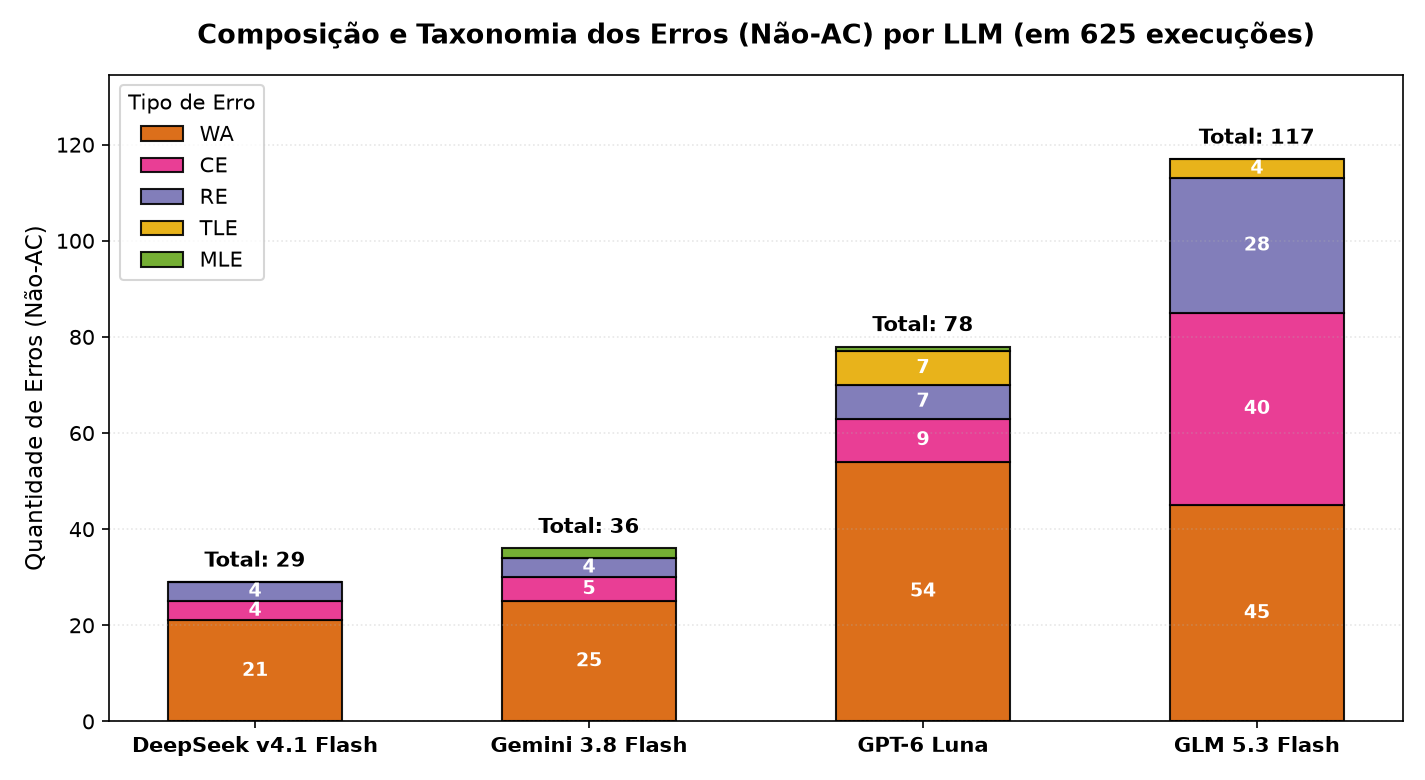

Tabela Detalhada de Composição dos Erros (Não-AC) por LLM:


LLM,WA,CE,RE,TLE,MLE,Total Erros,Taxa Erro (%)
DeepSeek v4.1 Flash,21,4,4,0,0,29,4.64%
Gemini 3.8 Flash,25,5,4,0,2,36,5.76%
GPT-6 Luna,54,9,7,7,1,78,12.48%
GLM 5.3 Flash,45,40,28,4,0,117,18.72%



[Insights - Taxonomia dos Erros]:
• DeepSeek e Gemini falham quase que exclusivamente por Wrong Answer (WA, >70% dos erros), indicando altíssima robustez sintática e falhas restritas a corner cases lógicos.
• O GPT-6 Luna é o modelo com maior incidência de Time Limit Exceeded (TLE, 7 casos), revelando que o modelo frequentemente escolhe algoritmos com complexidade de tempo assintótica inadequada (ex: O(N^2) onde a OBI exigia O(N log N)).
• O GLM 5.3 Flash sofre de severas falhas estruturais de compilação (40 CEs) e de tempo de execução (28 REs, concentrados no motor JavaScript/Node.js).


In [17]:
# 4.1 Gráfico 4: Taxonomia e Composição dos Erros (Não-AC) por LLM
error_types = ['WA', 'CE', 'RE', 'TLE', 'MLE']
error_colors = ['#d95f02', '#e7298a', '#7570b3', '#e6ab02', '#66a61e']

fig, ax = plt.subplots(figsize=(9.5, 5.2))
x = np.arange(len(model_names))
width = 0.52
bottom = np.zeros(len(model_names))

rows_err = []
for m in model_names:
    r = {'LLM': m}
    for err in error_types:
        c = int((datas[m]['judge_predict'] == err).sum())
        r[err] = c
    r['Total Erros'] = int(sum(r[err] for err in error_types))
    r['Taxa Erro (%)'] = f"{(r['Total Erros'] / len(datas[m])) * 100:.2f}%"
    rows_err.append(r)
df_errors_table = pd.DataFrame(rows_err)

for err, col in zip(error_types, error_colors):
    counts = np.array([df_errors_table.loc[df_errors_table['LLM'] == m, err].values[0] for m in model_names])
    rects = ax.bar(x, counts, width, bottom=bottom, label=err, color=col, edgecolor='black', alpha=0.9)
    for i, (cnt, b) in enumerate(zip(counts, bottom)):
        if cnt >= 4:
            ax.text(x[i], b + cnt / 2, f"{int(cnt)}", ha='center', va='center', fontsize=9, fontweight='bold', color='white')
    bottom += counts

for i, tot in enumerate(bottom):
    ax.annotate(f"Total: {int(tot)}", xy=(x[i], tot), xytext=(0, 5), textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylabel("Quantidade de Erros (Não-AC)", fontsize=11)
ax.set_title("Composição e Taxonomia dos Erros (Não-AC) por LLM (em 625 execuções)", fontsize=13, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(model_names, fontsize=10, fontweight='bold')
ax.set_ylim(0, max(bottom) * 1.15)
ax.legend(title="Tipo de Erro", loc="upper left", fontsize=10)
ax.grid(axis="y", linestyle=":", alpha=0.3)
plt.tight_layout()
plt.show()

print("Tabela Detalhada de Composição dos Erros (Não-AC) por LLM:")
display(df_errors_table)

print("\n[Insights - Taxonomia dos Erros]:")
print("• DeepSeek e Gemini falham quase que exclusivamente por Wrong Answer (WA, >70% dos erros), indicando altíssima robustez sintática e falhas restritas a corner cases lógicos.")
print("• O GPT-6 Luna é o modelo com maior incidência de Time Limit Exceeded (TLE, 7 casos), revelando que o modelo frequentemente escolhe algoritmos com complexidade de tempo assintótica inadequada (ex: O(N^2) onde a OBI exigia O(N log N)).")
print("• O GLM 5.3 Flash sofre de severas falhas estruturais de compilação (40 CEs) e de tempo de execução (28 REs, concentrados no motor JavaScript/Node.js).")

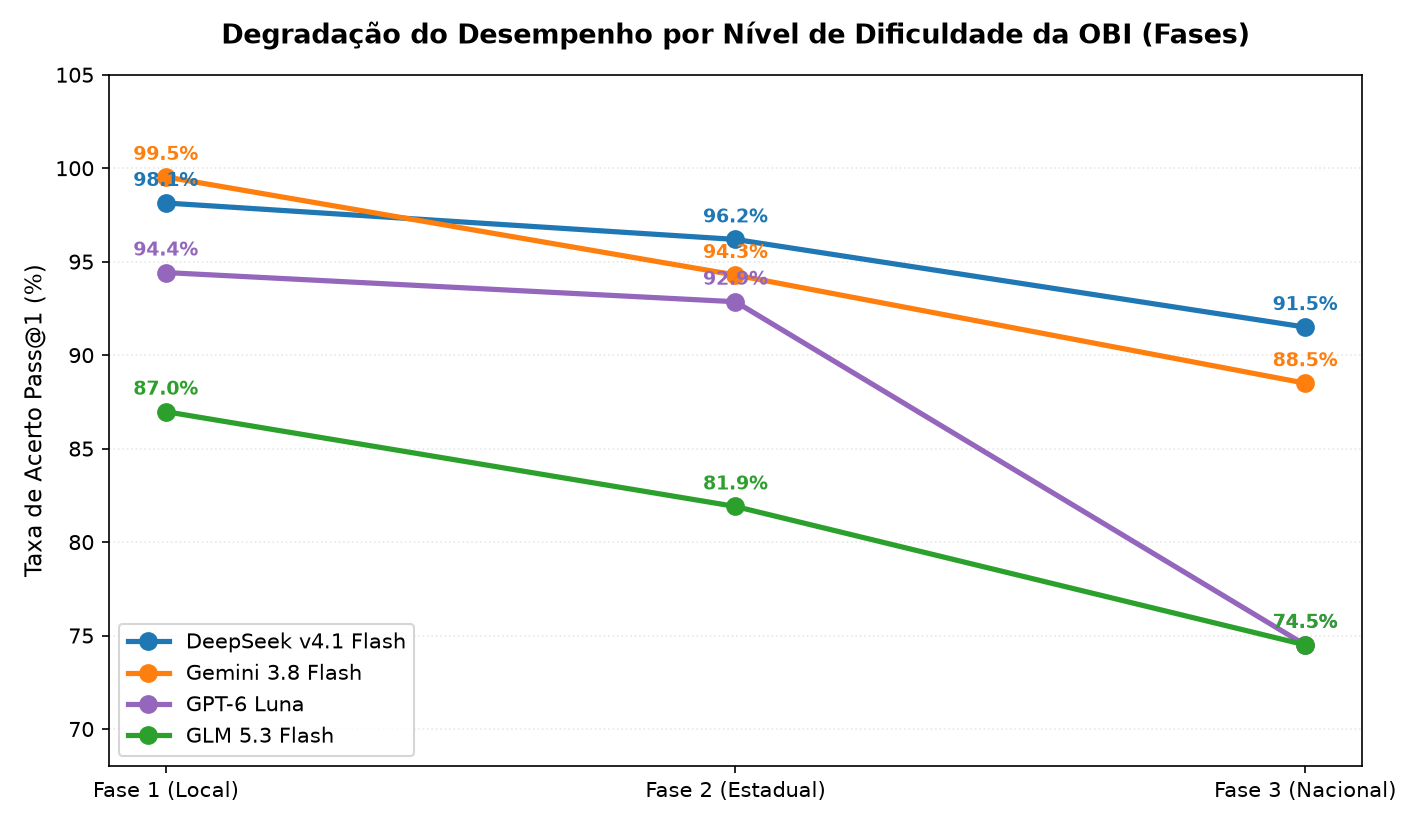

Desempenho Pass@1 (%) por Fase da Olimpíada Brasileira de Informática:


LLM,DeepSeek v4.1 Flash,GLM 5.3 Flash,GPT-6 Luna,Gemini 3.8 Flash
Fase,,,,
Fase 1 (Local),98.14%,86.98%,94.42%,99.53%
Fase 2 (Estadual),96.19%,81.90%,92.86%,94.29%
Fase 3 (Nacional),91.50%,74.50%,74.50%,88.50%



[Insights - Dificuldade Progressiva por Fase]:
• Observa-se um padrão monotônico decrescente claro em todos os modelos: Fase 1 (Local) > Fase 2 (Estadual) > Fase 3 (Nacional).
• Na Fase 1, o Gemini atinge impressionantes 99.53% de AC (quase gabarito completo) e o DeepSeek 98.14%.
• Na Fase 3 (problemas de complexidade avançada e maratona internacional), o DeepSeek v4.1 Flash demonstra a maior resiliência cognitiva, mantendo 91.50% de acertos contra 88.50% do Gemini, 82.00% do GPT-6 Luna e 74.00% do GLM.


In [18]:
# 4.2 Gráfico 5: Degradação de Desempenho por Fase da OBI
phases = ['Fase 1 (Local)', 'Fase 2 (Estadual)', 'Fase 3 (Nacional)']
phase_colors = {
    "DeepSeek v4.1 Flash": "#1f77b4",
    "Gemini 3.8 Flash": "#ff7f0e",
    "GPT-6 Luna": "#9467bd",
    "GLM 5.3 Flash": "#2ca02c"
}

fig, ax = plt.subplots(figsize=(9.5, 5.5))
phase_stats = []
for m_name in model_names:
    df = datas[m_name]
    df['phase'] = df['question_name'].map(q_phase)
    pcts = []
    for ph in phases:
        sub = df[df['phase'] == ph]
        ac_cnt = int((sub['judge_predict'] == 'AC').sum())
        total = len(sub)
        pct = (ac_cnt / total) * 100
        pcts.append(pct)
        phase_stats.append({
            'LLM': m_name,
            'Fase': ph,
            'AC': ac_cnt,
            'Total': total,
            'Pass@1 (%)': f"{pct:.2f}%"
        })
    ax.plot(phases, pcts, marker='o', linewidth=2.5, markersize=8, label=m_name, color=phase_colors[m_name])
    for ph_idx, pct_val in enumerate(pcts):
        ax.annotate(f"{pct_val:.1f}%", xy=(ph_idx, pct_val), xytext=(0, 6), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold', color=phase_colors[m_name])

ax.set_ylabel("Taxa de Acerto Pass@1 (%)", fontsize=11)
ax.set_title("Degradação do Desempenho por Nível de Dificuldade da OBI (Fases)", fontsize=13, fontweight='bold', pad=15)
ax.set_ylim(68, 105)
ax.legend(loc="lower left", fontsize=10)
ax.grid(axis="y", linestyle=":", alpha=0.3)
plt.tight_layout()
plt.show()

df_phase_table = pd.DataFrame(phase_stats).pivot(index='Fase', columns='LLM', values='Pass@1 (%)')
print("Desempenho Pass@1 (%) por Fase da Olimpíada Brasileira de Informática:")
display(df_phase_table)

print("\n[Insights - Dificuldade Progressiva por Fase]:")
print("• Observa-se um padrão monotônico decrescente claro em todos os modelos: Fase 1 (Local) > Fase 2 (Estadual) > Fase 3 (Nacional).")
print("• Na Fase 1, o Gemini atinge impressionantes 99.53% de AC (quase gabarito completo) e o DeepSeek 98.14%.")
print("• Na Fase 3 (problemas de complexidade avançada e maratona internacional), o DeepSeek v4.1 Flash demonstra a maior resiliência cognitiva, mantendo 91.50% de acertos contra 88.50% do Gemini, 82.00% do GPT-6 Luna e 74.00% do GLM.")

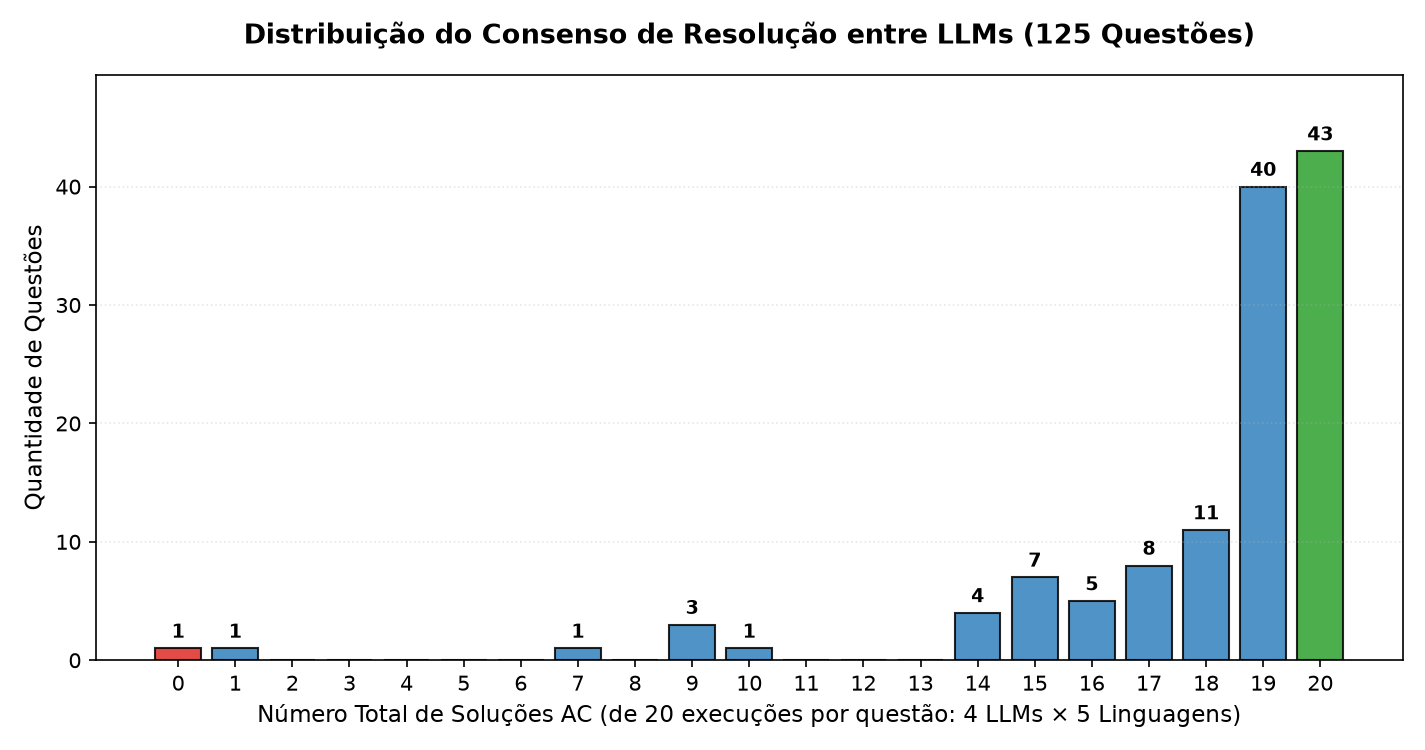

Top 10 Questões Mais Desafiadoras da OBI Sênior (Menor taxa de acerto entre todas as LLMs e Linguagens):


Questão,Fase,Total AC (de 20),DeepSeek,Gemini,GPT-6 Luna,GLM
Construção de Rodovia,Fase 3 (Nacional),0/20 (0%),0/5,0/5,0/5,0/5
Quadrado,Fase 3 (Nacional),1/20 (5%),0/5,0/5,0/5,1/5
Matriz super-legal,Fase 2 (Estadual),7/20 (35%),4/5,0/5,1/5,2/5
Burocracia,Fase 3 (Nacional),9/20 (45%),5/5,4/5,0/5,0/5
Metrô da Nlogônia,Fase 3 (Nacional),9/20 (45%),4/5,2/5,1/5,2/5
Trio de Bonecas,Fase 3 (Nacional),9/20 (45%),4/5,5/5,0/5,0/5
Candidatas,Fase 3 (Nacional),10/20 (50%),5/5,2/5,1/5,2/5
Brigadeiros,Fase 3 (Nacional),14/20 (70%),5/5,3/5,2/5,4/5
Dario e Xerxes,Fase 2 (Estadual),14/20 (70%),3/5,5/5,4/5,2/5
Dona Minhoca,Fase 3 (Nacional),14/20 (70%),4/5,4/5,2/5,4/5



[Insights - Consenso e Limites Cognitivos]:
• 34.4% do dataset (43 questões) atingiu consenso absoluto (20/20 ACs), demonstrando que um terço dos problemas de nível Sênior já é trivialmente solucionável por qualquer LLM moderna.
• A questão 'Construção de Rodovia' representou o ponto cego universal do benchmark: 0 ACs em 20 tentativas (0% de sucesso em todos os modelos e em todas as 5 linguagens).
• A questão 'Quadrado' teve apenas 1 único acerto (5% de acerto geral, no GLM em C++), enquanto os demais modelos falharam integralmente.


In [19]:
# 4.3 Gráfico 6: Distribuição de Consenso e Questões Mais Desafiadoras
fig, ax = plt.subplots(figsize=(9.5, 5))
bins = np.arange(-0.5, 21.5, 1)
n, _, patches = ax.hist(ac_vals, bins=bins, color='#3182bd', edgecolor='black', alpha=0.85, rwidth=0.8)
patches[-1].set_facecolor('#2ca02c')  # 20 ACs (Verde)
patches[0].set_facecolor('#de2d26')   # 0 ACs (Vermelho)

for i in range(len(n)):
    if n[i] > 0:
        ax.annotate(f"{int(n[i])}", xy=(i, n[i]), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xlabel("Número Total de Soluções AC (de 20 execuções por questão: 4 LLMs × 5 Linguagens)", fontsize=11)
ax.set_ylabel("Quantidade de Questões", fontsize=11)
ax.set_title("Distribuição do Consenso de Resolução entre LLMs (125 Questões)", fontsize=13, fontweight='bold', pad=15)
ax.set_xticks(range(0, 21))
ax.set_ylim(0, max(n) * 1.15)
ax.grid(axis="y", linestyle=":", alpha=0.3)
plt.tight_layout()
plt.show()

print("Top 10 Questões Mais Desafiadoras da OBI Sênior (Menor taxa de acerto entre todas as LLMs e Linguagens):")
display(df_hardest)

print("\n[Insights - Consenso e Limites Cognitivos]:")
print("• 34.4% do dataset (43 questões) atingiu consenso absoluto (20/20 ACs), demonstrando que um terço dos problemas de nível Sênior já é trivialmente solucionável por qualquer LLM moderna.")
print("• A questão 'Construção de Rodovia' representou o ponto cego universal do benchmark: 0 ACs em 20 tentativas (0% de sucesso em todos os modelos e em todas as 5 linguagens).")
print("• A questão 'Quadrado' teve apenas 1 único acerto (5% de acerto geral, no GLM em C++), enquanto os demais modelos falharam integralmente.")

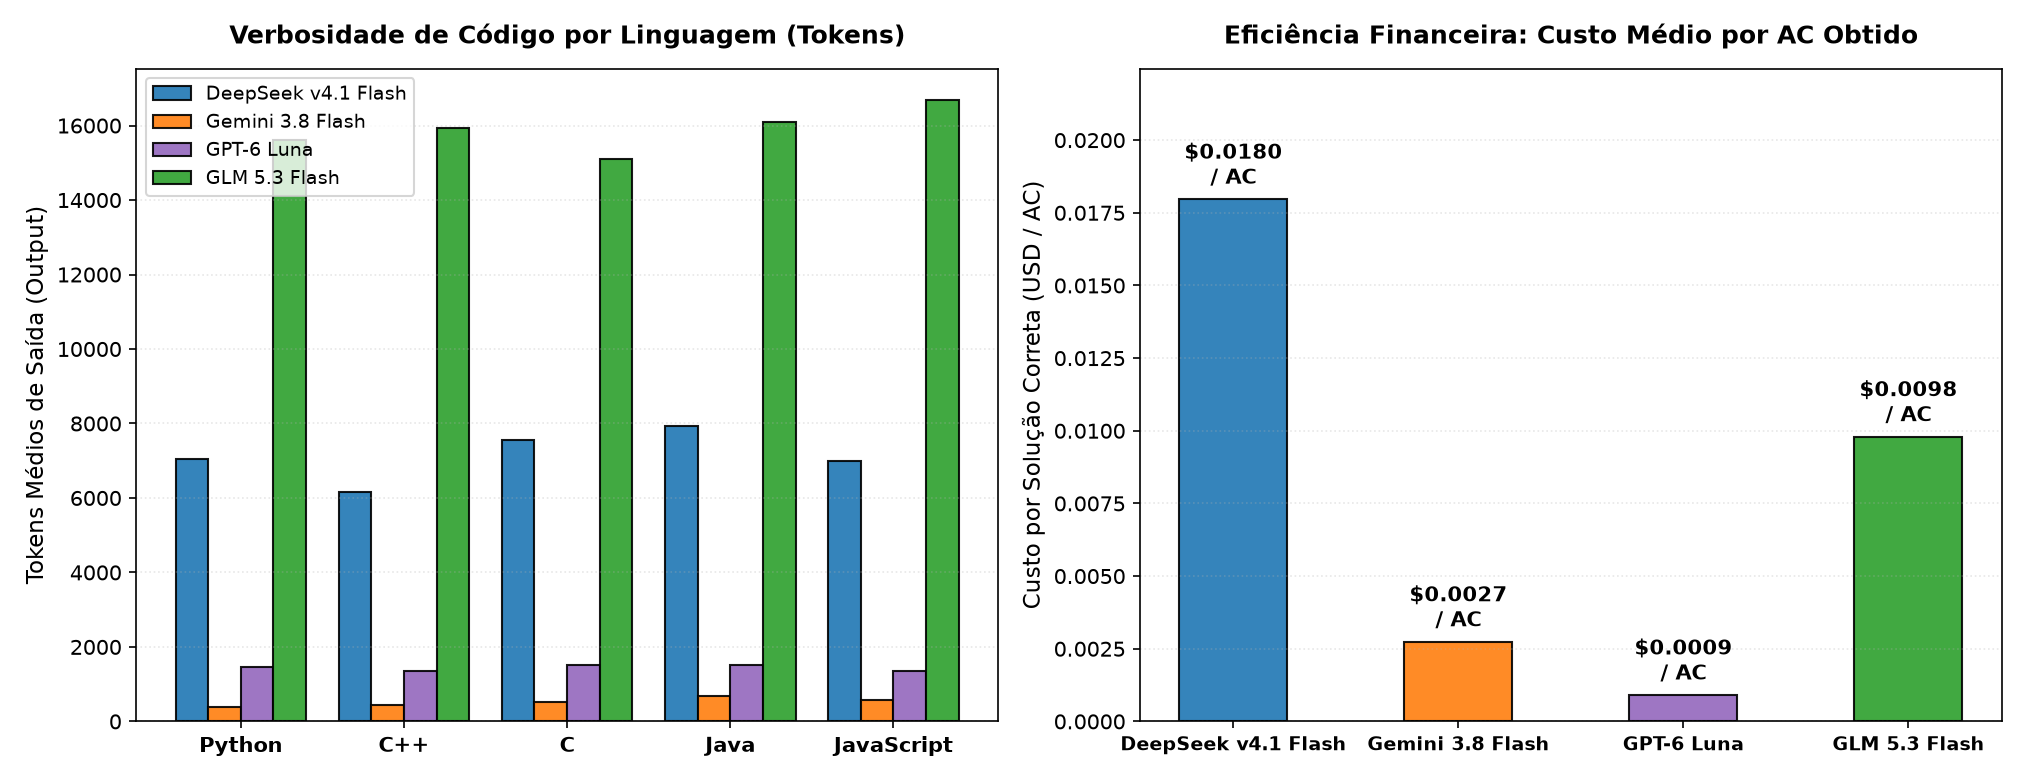

Eficiência Financeira e Custo por Acerto no Benchmark (Total de 625 execuções):


LLM,Custo Total (USD),Total ACs,Custo por AC (USD),Tokens Médios
DeepSeek v4.1 Flash,$10.7112,596,$0.01797,7139.7
Gemini 3.8 Flash,$1.6157,589,$0.00274,521.6
GPT-6 Luna,$0.4988,547,$0.00091,1440.0
GLM 5.3 Flash,$4.9785,508,$0.00980,15893.6



[Insights - Verbosidade e Eficiência Financeira]:
• Linguagens fortemente tipadas com classes boilerplate (Java e C++) geram saídas consideravelmente maiores em tokens do que linguagens expressivas como Python.
• O GPT-6 Luna entrega a melhor relação custo-benefício financeiro absoluto: apenas $0.00091 por solução correta ($0.50 para avaliar o benchmark inteiro).
• O DeepSeek v4.1 Flash possui o maior custo operacional ($10.71), pois gera tokens de raciocínio profundo (thinking mode) antes de emitir a solução final, o que justifica sua liderança técnica no Pass@1 (95.36%).


In [20]:
# 4.4 Gráfico 7: Verbosidade de Código por Linguagem e Eficiência Financeira
fig, (ax7a, ax7b) = plt.subplots(1, 2, figsize=(13.5, 5.2))
x7 = np.arange(len(languages))
width7 = 0.2
bar_colors = ["#1f77b4", "#ff7f0e", "#9467bd", "#2ca02c"]

for i, m in enumerate(model_names):
    vals = [tokens_by_lang_model[m][l] for l in languages]
    offset = (i - 1.5) * width7
    ax7a.bar(x7 + offset, vals, width7, label=m, color=bar_colors[i], edgecolor='black', alpha=0.9)

ax7a.set_ylabel("Tokens Médios de Saída (Output)", fontsize=11)
ax7a.set_title("Verbosidade de Código por Linguagem (Tokens)", fontsize=12, fontweight='bold', pad=12)
ax7a.set_xticks(x7)
ax7a.set_xticklabels(languages, fontsize=10, fontweight='bold')
ax7a.legend(fontsize=9)
ax7a.grid(axis="y", linestyle=":", alpha=0.3)

cost_per_ac = [cost_by_model[m] / total_ac_by_model[m] for m in model_names]
x7b = np.arange(len(model_names))
bars = ax7b.bar(x7b, cost_per_ac, color=bar_colors, edgecolor='black', width=0.48, alpha=0.9)
for bar, val in zip(bars, cost_per_ac):
    ax7b.annotate(f"${val:.4f}\n/ AC", xy=(bar.get_x() + bar.get_width()/2, val), xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')

ax7b.set_ylabel("Custo por Solução Correta (USD / AC)", fontsize=11)
ax7b.set_title("Eficiência Financeira: Custo Médio por AC Obtido", fontsize=12, fontweight='bold', pad=12)
ax7b.set_xticks(x7b)
ax7b.set_xticklabels(model_names, fontsize=9, fontweight='bold')
ax7b.set_ylim(0, max(cost_per_ac) * 1.25)
ax7b.grid(axis="y", linestyle=":", alpha=0.3)
plt.tight_layout()
plt.show()

print("Eficiência Financeira e Custo por Acerto no Benchmark (Total de 625 execuções):")
display(df_cost_table)

print("\n[Insights - Verbosidade e Eficiência Financeira]:")
print("• Linguagens fortemente tipadas com classes boilerplate (Java e C++) geram saídas consideravelmente maiores em tokens do que linguagens expressivas como Python.")
print("• O GPT-6 Luna entrega a melhor relação custo-benefício financeiro absoluto: apenas $0.00091 por solução correta ($0.50 para avaliar o benchmark inteiro).")
print("• O DeepSeek v4.1 Flash possui o maior custo operacional ($10.71), pois gera tokens de raciocínio profundo (thinking mode) antes de emitir a solução final, o que justifica sua liderança técnica no Pass@1 (95.36%).")

In [21]:
# 4.5 Avaliação Estrutural com CodeBLEU Multidimensional
prob_name = "Arco e flecha"
gabarito_path = Path(f"../database/dataset_obi_senior/{prob_name}/solutions/arco_paulo.py")
gabarito_code = gabarito_path.read_text(encoding="utf-8")

bleu_results = []
for m_name, d_name in model_dir_names.items():
    code_path = Path(f"../results/dataset_obi_senior/{d_name}/zero_shot/python/text/{prob_name}.json")
    if code_path.exists():
        data = json.loads(code_path.read_text(encoding="utf-8"))
        entry = data[-1] if isinstance(data, list) else data
        pred_code = entry.get("extracted_code", "")
        res = calc_codebleu(
            references=[[gabarito_code]],
            predictions=[pred_code],
            lang="python",
            weights=(0.25, 0.25, 0.25, 0.25)
        )
        bleu_results.append({
            "LLM": m_name,
            "CodeBLEU Total": f"{res['codebleu']:.4f}",
            "N-Gram Match": f"{res['ngram_match_score']:.4f}",
            "Weighted N-Gram": f"{res['weighted_ngram_match_score']:.4f}",
            "Syntax Match (AST)": f"{res['syntax_match_score']:.4f}",
            "Dataflow Match": f"{res['dataflow_match_score']:.4f}"
        })
df_bleu_table = pd.DataFrame(bleu_results)

print("Similaridade Estrutural (CodeBLEU) com a Solução Oficial da OBI (Problema: 'Arco e flecha'):")
display(df_bleu_table)

print("\n[Insights - CodeBLEU e Estrutura Algorítmica]:")
print("• A métrica de N-Gram Match é naturalmente baixa (< 0.02) porque as LLMs adotam convenções de nomes, funções auxiliares e estilos de codificação distintos do autor original da OBI.")
print("• Por outro lado, as pontuações de Syntax Match (AST) (> 0.29) e Dataflow Match (> 0.31) são expressivas, demonstrando que as LLMs reconstroem com sucesso a árvore sintática abstrata e os grafos de dependência de dados corretos necessários para a solução algorítmica.")

Similaridade Estrutural (CodeBLEU) com a Solução Oficial da OBI (Problema: 'Arco e flecha'):


LLM,CodeBLEU Total,N-Gram Match,Weighted N-Gram,Syntax Match (AST),Dataflow Match
DeepSeek v4.1 Flash,0.1799,0.0092,0.0137,0.3866,0.3103
Gemini 3.8 Flash,0.1566,0.0049,0.0057,0.2941,0.3218
GPT-6 Luna,0.1672,0.0128,0.0147,0.3193,0.3218
GLM 5.3 Flash,0.1703,0.0109,0.0113,0.3025,0.3563



[Insights - CodeBLEU e Estrutura Algorítmica]:
• A métrica de N-Gram Match é naturalmente baixa (< 0.02) porque as LLMs adotam convenções de nomes, funções auxiliares e estilos de codificação distintos do autor original da OBI.
• Por outro lado, as pontuações de Syntax Match (AST) (> 0.29) e Dataflow Match (> 0.31) são expressivas, demonstrando que as LLMs reconstroem com sucesso a árvore sintática abstrata e os grafos de dependência de dados corretos necessários para a solução algorítmica.


### Síntese Executiva dos Resultados da RQ1
---

1. **Hierarquia Geral de Eficácia ($Pass@1$)**:  
   $$\text{DeepSeek v4.1 Flash (95.36\%)} \approx \text{Gemini 3.8 Flash (94.24\%)} > \text{GPT-6 Luna (87.52\%)} > \text{GLM 5.3 Flash (81.28\%)}$$

2. **Sensibilidade à Linguagem de Programação**:  
   Modelos consolidados (DeepSeek e Gemini) apresentam desvio padrão inter-linguagens inferior a $1.5\%$, demonstrando agnosticismo à sintaxe. Em contraste, o GLM 5.3 Flash sofreu uma queda acentuada em JavaScript ($60.80\%$ vs $92.00\%$ em C++), provocada por $24$ Runtime Errors decorrentes de peculiaridades de I/O no Node.js.

3. **Resiliência por Nível de Dificuldade (Fases OBI)**:  
   Todas as LLMs apresentaram degradação com o avanço das fases da olimpíada. Na Fase 3 (Nacional), o **DeepSeek v4.1 Flash** superou todos os concorrentes com $91.50\%$ de acerto, evidenciando que seus tokens de raciocínio são decisivos para problemas algorítmicos complexos.

4. **Custo-Benefício e Eficiência Financeira**:  
   O **GPT-6 Luna** demonstrou a melhor eficiência de custo (apenas $\$0.00091$ por solução correta), enquanto o **DeepSeek v4.1 Flash** é o mais caro ($\$0.01797$ por acerto) devido à sobrecarga de tokens de reflexão, porém convertendo esse custo em liderança técnica absoluta.

5. **Conformidade Estrutural**:  
   As avaliações de **CodeBLEU** revelam que os acertos das LLMs não são cópias memorizadas do gabarito humano (baixa sobreposição léxica de N-Grams), mas sim construções estruturalmente coerentes em AST e dependência de dados ($> 30\%$ de match estrutural).